# D1ECD – Estatística para Ciência de Dados
## Atividade Avaliativa 02 – Teste ANOVA

**Nome:** Rodrigo Gimenes Rodrigues  
**Matrícula:** CP3071782  
**Curso:** Especialização em Ciência de Dados  
**Período/Ano:** 2026/2  
**Campus:** Campinas  
**Turno:** EAD  
**Professor:** Kakimoto


## Conjunto de dados

Tempo de permanência no site, em minutos. São 10 usuários em cada algoritmo (A, B, C e D), amostras independentes, no mesmo período.


In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

dados = {
    'Algoritmo_A': [18.2, 20.1, 17.5, 19.8, 21.0, 18.9, 17.8, 20.5, 19.1, 18.6],
    'Algoritmo_B': [22.5, 24.1, 23.0, 21.8, 25.2, 23.9, 22.1, 24.5, 23.7, 24.0],
    'Algoritmo_C': [19.0, 18.5, 19.8, 20.2, 17.9, 19.1, 18.8, 20.0, 19.3, 18.7],
    'Algoritmo_D': [25.0, 27.3, 26.1, 24.8, 28.0, 26.5, 25.9, 27.0, 26.2, 25.5]
}

df = pd.DataFrame(dados)
df

,Algoritmo_A,Algoritmo_B,Algoritmo_C,Algoritmo_D
0,18.2,22.5,19.0,25.0
1,20.1,24.1,18.5,27.3
2,17.5,23.0,19.8,26.1
3,19.8,21.8,20.2,24.8
4,21.0,25.2,17.9,28.0
5,18.9,23.9,19.1,26.5
6,17.8,22.1,18.8,25.9
7,20.5,24.5,20.0,27.0
8,19.1,23.7,19.3,26.2
9,18.6,24.0,18.7,25.5


## Parte 1 – Hipóteses e análise exploratória

H0: o tempo médio de permanência é o mesmo nos quatro algoritmos. Ou seja, μA = μB = μC = μD.

H1: pelo menos um algoritmo tem média diferente dos demais.


In [2]:
resumo = pd.DataFrame({
    'Média': df.mean(),
    'Desvio padrão': df.std(ddof=1),
    'Mediana': df.median()
})

resumo.round(2)

,Média,Desvio padrão,Mediana
Algoritmo_A,19.15,1.17,19.00
Algoritmo_B,23.48,1.10,23.80
Algoritmo_C,19.13,0.71,19.05
Algoritmo_D,26.23,1.01,26.15


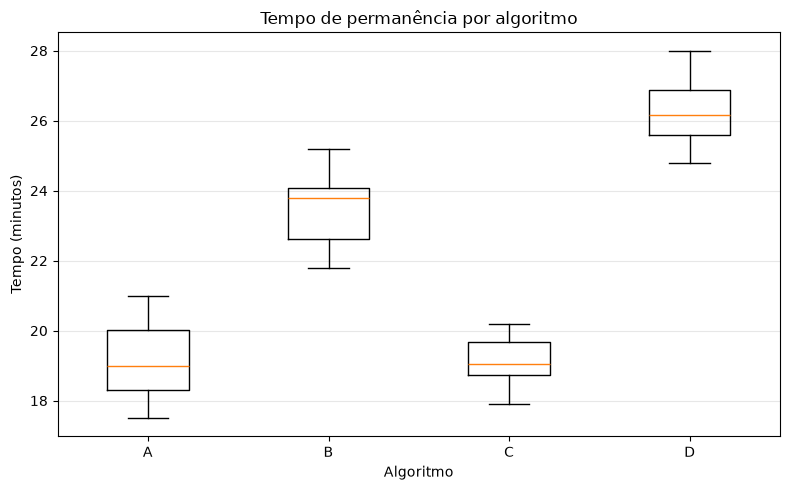

In [3]:
plt.figure(figsize=(8, 5))
plt.boxplot([df[col] for col in df.columns], tick_labels=['A', 'B', 'C', 'D'])
plt.title('Tempo de permanência por algoritmo')
plt.xlabel('Algoritmo')
plt.ylabel('Tempo (minutos)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Comentário – Parte 1

Rodando o código, as médias foram 19,15 (A), 23,48 (B), 19,13 (C) e 26,23 (D). A e C praticamente empataram. O B ficou cerca de 4,3 minutos acima deles, e o D uns 7 minutos acima.

O desvio padrão ficou entre 0,71 e 1,17. Dentro de cada grupo o tempo varia pouco, perto de 1 minuto. A mediana acompanha a média em todos (19,00, 23,80, 19,05 e 26,15), então não parece ter um ponto isolado puxando a conta.

No boxplot as caixas de A e C se sobrepõem. B fica acima das duas, e D mais acima ainda, sem encostar no B. O gráfico já sugere diferença, mas quem decide é o teste.


## Parte 2 – Pressupostos

Antes da ANOVA, Shapiro-Wilk em cada grupo (normalidade) e teste de Levene (variâncias). Usei α = 0,05.


In [4]:
for coluna in df.columns:
    estat, p = stats.shapiro(df[coluna])
    print(f'{coluna}: W = {estat:.4f}, p = {p:.4f}')

estat_lev, p_lev = stats.levene(
    df['Algoritmo_A'],
    df['Algoritmo_B'],
    df['Algoritmo_C'],
    df['Algoritmo_D']
)
print(f'Levene: W = {estat_lev:.4f}, p = {p_lev:.4f}')

Algoritmo_A: W = 0.9660, p = 0.8513
Algoritmo_B: W = 0.9568, p = 0.7485
Algoritmo_C: W = 0.9715, p = 0.9042
Algoritmo_D: W = 0.9770, p = 0.9472
Levene: W = 0.8183, p = 0.4923


### Comentário – Parte 2

Nenhum Shapiro rejeitou a normalidade. Os p foram 0,851 (A), 0,749 (B), 0,904 (C) e 0,947 (D). Com n = 10 o teste não é muito sensível, mas os p estão folgados e os boxplots não mostram cauda esquisita.

O Levene deu W = 0,82 e p = 0,492. Também acima de 0,05, então não rejeito a igualdade das variâncias. O grupo C é um pouco mais concentrado (desvio 0,71, contra cerca de 1,1 nos outros), só que essa diferença não passou no teste. Dá para seguir com a ANOVA.


## Parte 3 – ANOVA de um fator

O `f_oneway` devolve F e o p-valor, mas não a tabela com somas de quadrados. Montei SQ, gl e QM pelas fórmulas e conferi o F com o scipy.


In [5]:
grupos = [df[c] for c in df.columns]
n = len(df)
k = len(grupos)
N = n * k

medias = df.mean()
media_geral = np.mean(df.to_numpy())

sq_entre = (n * (medias - media_geral) ** 2).sum()
sq_dentro = ((df - medias) ** 2).sum().sum()

gl_entre = k - 1
gl_dentro = N - k
qm_entre = sq_entre / gl_entre
qm_dentro = sq_dentro / gl_dentro
f_calc = qm_entre / qm_dentro

f_stat, p_valor = stats.f_oneway(*grupos)

tabela = pd.DataFrame({
    'SQ': [sq_entre, sq_dentro],
    'gl': [gl_entre, gl_dentro],
    'QM': [qm_entre, qm_dentro],
    'F': [f_calc, np.nan],
    'p-valor': [p_valor, np.nan]
}, index=['Entre grupos', 'Dentro dos grupos'])

print('F pela fórmula:', round(f_calc, 4))
print('F do f_oneway:', round(float(f_stat), 4))
print('p-valor:', p_valor)
tabela

F pela fórmula: 118.3748
F do f_oneway: 118.3748
p-valor: 1.0493909399905641e-18


,SQ,gl,QM,F,p-valor
Entre grupos,364.42675,3,121.475583,118.374821,1.049391e-18
Dentro dos grupos,36.94300,36,1.026194,NaN,NaN


### Comentário – Parte 3

O F deu 118,37 e o p-valor 1,05e-18. Bem menor que 0,05, então rejeito H0. O tempo médio não é o mesmo nos quatro algoritmos.

A soma dos quadrados entre grupos (364,43) é quase dez vezes a de dentro (36,94). A maior parte da variação está entre os algoritmos, não entre os usuários do mesmo algoritmo. Por isso o F ficou tão grande. Graus de liberdade: 3 entre grupos e 36 dentro. Os quadrados médios foram 121,48 e 1,03.


## Parte 4 – Tukey e conclusão

Como H0 foi rejeitada, rodei o Tukey HSD para ver quais pares diferem. A diferença abaixo é a média do primeiro menos a média do segundo.


In [6]:
tukey = stats.tukey_hsd(*grupos)
ic = tukey.confidence_interval(confidence_level=0.95)
nomes = ['A', 'B', 'C', 'D']

print(f'{"Par":<8} {"Diferença":>10} {"IC inf":>8} {"IC sup":>8} {"p-valor":>12}')
for i in range(len(nomes)):
    for j in range(i + 1, len(nomes)):
        diff = tukey.statistic[i, j]
        p = tukey.pvalue[i, j]
        print(f'{nomes[i]} - {nomes[j]:<4} {diff:10.2f} {ic.low[i, j]:8.2f} {ic.high[i, j]:8.2f} {p:12.4g}')

Par       Diferença   IC inf   IC sup      p-valor
A - B         -4.33    -5.55    -3.11    1.219e-10
A - C          0.02    -1.20     1.24            1
A - D         -7.08    -8.30    -5.86    5.107e-15
B - C          4.35     3.13     5.57    1.081e-10
B - D         -2.75    -3.97    -1.53    3.264e-06
C - D         -7.10    -8.32    -5.88    5.107e-15


### Comentário – Parte 4

Diferença negativa quer dizer que o segundo algoritmo segurou o usuário por mais tempo. Só o par A–C não foi significativo: 0,02 minuto, p praticamente 1, e o intervalo de confiança passa pelo zero. Nos outros pares o p ficou muito abaixo de 0,05 e o intervalo nem chega perto de zero. A ordem ficou D > B > A = C.

O melhor tempo de permanência foi o do algoritmo D, com média de 26,23 minutos. O B ficou em segundo, com 23,48. A diferença entre os dois é de 2,75 minutos e o Tukey separou os dois com folga. A e C ficaram empatados, em torno de 19,1 minutos.

Para a equipe de produto, eu adotaria o D como algoritmo padrão e deixaria o B só se o D esbarrar em algum custo ou restrição que esse experimento não mediu. A e C eu tiraria. Ainda assim, antes de fechar, eu cruzaria o tempo no site com conversão e valor do pedido, porque ficar mais tempo navegando não garante que a pessoa comprou mais. No critério que a empresa pediu aqui, o D é a escolha.
